## Part A: Conceptual Foundation

**1. What are Ensemble Learning Methods and why are they effective?**  
Ensemble learning combines predictions from multiple machine learning models. It can give better accuracy and more stable results than using only one model because different models can learn different patterns.

**2. Difference between Bagging, Boosting, and Voting**  
- **Bagging:** Trains models independently on different samples of the training data and combines their predictions. It mainly reduces variance.
- **Boosting:** Trains models one after another, with later models trying to correct earlier errors. It can reduce bias.
- **Voting:** Combines predictions from different models. Hard voting uses the majority class, while soft voting averages predicted probabilities.

**3. What is the Bias–Variance Trade-off, and how do ensemble methods address it?**  
High bias means a model is too simple, while high variance means it changes too much with the training data. Bagging often reduces variance, while boosting can reduce bias by learning difficult patterns.

**4. Voting Classifier vs Stacking Ensemble**  
Voting combines the predictions of base models directly. Stacking uses the predictions of base models as inputs to another model called a meta-learner, which learns how to combine them.

**5. AdaBoost, Gradient Boosting, LightGBM, and XGBoost**  
- **AdaBoost:** Gives more attention to training examples that earlier models classified incorrectly.
- **Gradient Boosting:** Adds models sequentially to reduce the remaining loss.
- **LightGBM:** A fast gradient boosting library designed to work efficiently with large datasets.
- **XGBoost:** A gradient boosting library with regularization and other features to improve performance and control overfitting.


## Part B: Load and prepare the dataset

In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("data.csv")

df.columns = df.columns.str.strip()

print("Dataset shape:", df.shape)
display(df.head())
print("\\nColumn names:")
print(df.columns.tolist())
print("\\nMissing values:")
print(df.isnull().sum())


Dataset shape: (5200, 19)


,student_id,age,country_region,device_type,education_background,course_level,course_category,course_start_date,week_of_year,sessions,time_spent_hours,videos_watched,quiz_attempts,assignments_submitted,forum_posts,avg_quiz_score,attendance_rate,completion_status,final_score
0,700001,32,Europe,Laptop,Undergrad,Intermediate,Business,2024-03-18,12,1,7.6,1,6,1,1,53.3,0.655,0,49.8
1,700002,17,Europe,Laptop,Undergrad,Intermediate,Programming,2024-08-22,34,16,27.2,6,4,7,1,51.5,1.000,1,84.0
2,700003,25,Europe,Mobile,Graduate,Advanced,Programming,2024-09-28,39,6,7.1,16,2,2,0,62.2,0.810,0,62.5
3,700004,26,Asia,Mobile,Undergrad,Beginner,Design,2024-03-09,10,34,22.1,57,9,6,0,59.3,0.875,1,89.5
4,700005,26,Asia,Tablet,WorkingPro,Advanced,Business,2024-03-21,12,22,32.3,41,9,2,0,65.1,0.814,0,67.4


\nColumn names:
['student_id', 'age', 'country_region', 'device_type', 'education_background', 'course_level', 'course_category', 'course_start_date', 'week_of_year', 'sessions', 'time_spent_hours', 'videos_watched', 'quiz_attempts', 'assignments_submitted', 'forum_posts', 'avg_quiz_score', 'attendance_rate', 'completion_status', 'final_score']
\nMissing values:
student_id                 0
age                        0
country_region             0
device_type                0
education_background       0
course_level               0
course_category            0
course_start_date          0
week_of_year               0
sessions                   0
time_spent_hours         112
videos_watched             0
quiz_attempts              0
assignments_submitted      0
forum_posts                0
avg_quiz_score            81
attendance_rate           80
completion_status          0
final_score                0
dtype: int64


In [2]:

classification_target = "completion_status"
regression_target = "final_score"

if classification_target not in df.columns or regression_target not in df.columns:
    raise ValueError(
        "Please check the CSV column names. Required columns: "
        "'completion_status' and 'final_score'."
    )

class_df = df.dropna(subset=[classification_target]).copy()
reg_df = df.dropna(subset=[regression_target]).copy()

feature_columns = [
    col for col in df.columns
    if col not in [classification_target, regression_target, "student_id"]
]

X_class = class_df[feature_columns]
y_class = class_df[classification_target]

X_reg = reg_df[feature_columns]
y_reg = reg_df[regression_target]

print("Features:")
print(feature_columns)
print("\\nClassification target:", classification_target)
print("Regression target:", regression_target)


Features:
['age', 'country_region', 'device_type', 'education_background', 'course_level', 'course_category', 'course_start_date', 'week_of_year', 'sessions', 'time_spent_hours', 'videos_watched', 'quiz_attempts', 'assignments_submitted', 'forum_posts', 'avg_quiz_score', 'attendance_rate']
\nClassification target: completion_status
Regression target: final_score


### Preprocessing and train-test split

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

X_class_train, X_class_test, y_class_train, y_class_test = train_test_split(
    X_class, y_class, test_size=0.2, random_state=42, stratify=y_class
)

X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42
)

numeric_features = X_class.select_dtypes(include=np.number).columns.tolist()
categorical_features = [c for c in feature_columns if c not in numeric_features]

numeric_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_preprocessor, numeric_features),
    ("cat", categorical_preprocessor, categorical_features)
])

print("Training rows:", len(X_class_train))
print("Testing rows:", len(X_class_test))
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)


Training rows: 4160
Testing rows: 1040
Numeric features: ['age', 'week_of_year', 'sessions', 'time_spent_hours', 'videos_watched', 'quiz_attempts', 'assignments_submitted', 'forum_posts', 'avg_quiz_score', 'attendance_rate']
Categorical features: ['country_region', 'device_type', 'education_background', 'course_level', 'course_category', 'course_start_date']


## Part C: Bagging

In [18]:
from sklearn.ensemble import BaggingClassifier, BaggingRegressor
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    mean_absolute_error, mean_squared_error, r2_score
)

bagging_classifier = Pipeline([
    ("preprocessing", preprocessor),
    ("model", BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=42),
        n_estimators=50,
        random_state=42
    ))
])

bagging_classifier.fit(X_class_train, y_class_train)
bag_class_pred = bagging_classifier.predict(X_class_test)

print("Accuracy:", accuracy_score(y_class_test, bag_class_pred))
print("F1-score:", f1_score(y_class_test, bag_class_pred, average="weighted"))


Accuracy: 0.7240384615384615
F1-score: 0.718065268065268


In [17]:
bagging_regressor = Pipeline([
    ("preprocessing", preprocessor),
    ("model", BaggingRegressor(
        estimator=DecisionTreeRegressor(random_state=42),
        n_estimators=50,
        random_state=42
    ))
])

bagging_regressor.fit(X_reg_train, y_reg_train)
bag_reg_pred = bagging_regressor.predict(X_reg_test)

print("MAE:", mean_absolute_error(y_reg_test, bag_reg_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_reg_test, bag_reg_pred)))
print("R2:", r2_score(y_reg_test, bag_reg_pred))


MAE: 8.044640384615384
RMSE: 10.077179691491832
R2: 0.4564879697162276


## Part D: Boosting Algorithms

### AdaBoost

In [19]:
from sklearn.ensemble import AdaBoostClassifier, AdaBoostRegressor

ada_classifier = Pipeline([
    ("preprocessing", preprocessor),
    ("model", AdaBoostClassifier(n_estimators=50, random_state=42))
])
ada_classifier.fit(X_class_train, y_class_train)
ada_class_pred = ada_classifier.predict(X_class_test)

print(" Classifier Accuracy:", accuracy_score(y_class_test, ada_class_pred))
print(" Classifier F1-score:", f1_score(y_class_test, ada_class_pred, average="weighted"))

ada_regressor = Pipeline([
    ("preprocessing", preprocessor),
    ("model", AdaBoostRegressor(n_estimators=50, learning_rate=0.1, random_state=42))
])
ada_regressor.fit(X_reg_train, y_reg_train)
ada_reg_pred = ada_regressor.predict(X_reg_test)

print(" Regressor MAE:", mean_absolute_error(y_reg_test, ada_reg_pred))
print(" Regressor RMSE:", np.sqrt(mean_squared_error(y_reg_test, ada_reg_pred)))
print(" Regressor R2:", r2_score(y_reg_test, ada_reg_pred))


c:\Users\Priyansh\anaconda3\Lib\site-packages\sklearn\ensemble\_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(


 Classifier Accuracy: 0.7096153846153846
 Classifier F1-score: 0.7066985944025306
 Regressor MAE: 8.513532647835078
 Regressor RMSE: 10.496757873322343
 Regressor R2: 0.4102858958541238


### Gradient Boosting

In [20]:
from sklearn.ensemble import GradientBoostingClassifier, GradientBoostingRegressor

gb_classifier = Pipeline([
    ("preprocessing", preprocessor),
    ("model", GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, random_state=42))
])
gb_classifier.fit(X_class_train, y_class_train)
gb_class_pred = gb_classifier.predict(X_class_test)

print("  Classifier Accuracy:", accuracy_score(y_class_test, gb_class_pred))
print("  Classifier F1-score:", f1_score(y_class_test, gb_class_pred, average="weighted"))

gb_regressor = Pipeline([
    ("preprocessing", preprocessor),
    ("model", GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42))
])
gb_regressor.fit(X_reg_train, y_reg_train)
gb_reg_pred = gb_regressor.predict(X_reg_test)

print("  Regressor MAE:", mean_absolute_error(y_reg_test, gb_reg_pred))
print("  Regressor RMSE:", np.sqrt(mean_squared_error(y_reg_test, gb_reg_pred)))
print("  Regressor R2:", r2_score(y_reg_test, gb_reg_pred))


  Classifier Accuracy: 0.7298076923076923
  Classifier F1-score: 0.7246177688375335
  Regressor MAE: 7.844713482435213
  Regressor RMSE: 9.808568699331664
  Regressor R2: 0.4850768322835194


### LightGBM

In [21]:
try:
    from lightgbm import LGBMClassifier, LGBMRegressor

    lgbm_classifier = Pipeline([
        ("preprocessing", preprocessor),
        ("model", LGBMClassifier(n_estimators=100, learning_rate=0.05, random_state=42, verbosity=-1))
    ])
    lgbm_classifier.fit(X_class_train, y_class_train)
    lgbm_class_pred = lgbm_classifier.predict(X_class_test)

    print(" Classifier Accuracy:", accuracy_score(y_class_test, lgbm_class_pred))
    print(" Classifier F1-score:", f1_score(y_class_test, lgbm_class_pred, average="weighted"))

    lgbm_regressor = Pipeline([
        ("preprocessing", preprocessor),
        ("model", LGBMRegressor(n_estimators=100, learning_rate=0.05, random_state=42, verbosity=-1))
    ])
    lgbm_regressor.fit(X_reg_train, y_reg_train)
    lgbm_reg_pred = lgbm_regressor.predict(X_reg_test)

    print(" Regressor MAE:", mean_absolute_error(y_reg_test, lgbm_reg_pred))
    print(" Regressor RMSE:", np.sqrt(mean_squared_error(y_reg_test, lgbm_reg_pred)))
    print(" Regressor R2:", r2_score(y_reg_test, lgbm_reg_pred))
except ImportError:
    print("LightGBM is not installed. Run: %pip install lightgbm")


LightGBM is not installed. Run: %pip install lightgbm


### XGBoost

In [9]:
try:
    from xgboost import XGBClassifier, XGBRegressor

    from sklearn.preprocessing import LabelEncoder
    label_encoder = LabelEncoder()
    y_class_train_xgb = label_encoder.fit_transform(y_class_train)
    y_class_test_xgb = label_encoder.transform(y_class_test)

    xgb_classifier = Pipeline([
        ("preprocessing", preprocessor),
        ("model", XGBClassifier(
            n_estimators=100, max_depth=3, learning_rate=0.05,
            eval_metric="logloss", random_state=42
        ))
    ])
    xgb_classifier.fit(X_class_train, y_class_train_xgb)
    xgb_class_pred = xgb_classifier.predict(X_class_test)

    print(" Classifier Accuracy:", accuracy_score(y_class_test_xgb, xgb_class_pred))
    print(" Classifier F1-score:", f1_score(y_class_test_xgb, xgb_class_pred, average="weighted"))

    xgb_regressor = Pipeline([
        ("preprocessing", preprocessor),
        ("model", XGBRegressor(
            n_estimators=100, max_depth=3, learning_rate=0.05, random_state=42
        ))
    ])
    xgb_regressor.fit(X_reg_train, y_reg_train)
    xgb_reg_pred = xgb_regressor.predict(X_reg_test)

    print(" Regressor MAE:", mean_absolute_error(y_reg_test, xgb_reg_pred))
    print(" Regressor RMSE:", np.sqrt(mean_squared_error(y_reg_test, xgb_reg_pred)))
    print(" Regressor R2:", r2_score(y_reg_test, xgb_reg_pred))
except ImportError:
    print("XGBoost is not installed. Run: %pip install xgboost")


XGBoost Classifier Accuracy: 0.7346153846153847
XGBoost Classifier F1-score: 0.728312943353552
XGBoost Regressor MAE: 7.944560747880202
XGBoost Regressor RMSE: 9.914861529744824
XGBoost Regressor R2: 0.4738561936542084


## Part E: Voting and Stacking

In [10]:
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, VotingClassifier, VotingRegressor, StackingClassifier, StackingRegressor
from sklearn.linear_model import LogisticRegression, LinearRegression

voting_classifier = Pipeline([
    ("preprocessing", preprocessor),
    ("model", VotingClassifier(
        estimators=[
            ("tree", DecisionTreeClassifier(max_depth=5, random_state=42)),
            ("forest", RandomForestClassifier(n_estimators=50, random_state=42)),
            ("ada", AdaBoostClassifier(n_estimators=50, random_state=42))
        ],
        voting="hard"
    ))
])
voting_classifier.fit(X_class_train, y_class_train)
voting_class_pred = voting_classifier.predict(X_class_test)

print("Voting Classifier Accuracy:", accuracy_score(y_class_test, voting_class_pred))
print("Voting Classifier F1-score:", f1_score(y_class_test, voting_class_pred, average="weighted"))

soft_voting = Pipeline([
    ("preprocessing", preprocessor),
    ("model", VotingClassifier(
        estimators=[
            ("forest", RandomForestClassifier(n_estimators=50, random_state=42)),
            ("ada", AdaBoostClassifier(n_estimators=50, random_state=42))
        ],
        voting="soft"
    ))
])
soft_voting.fit(X_class_train, y_class_train)
soft_pred = soft_voting.predict(X_class_test)
print("Soft Voting Accuracy:", accuracy_score(y_class_test, soft_pred))


c:\Users\Priyansh\anaconda3\Lib\site-packages\sklearn\ensemble\_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(


Voting Classifier Accuracy: 0.7278846153846154
Voting Classifier F1-score: 0.7148001671714861


c:\Users\Priyansh\anaconda3\Lib\site-packages\sklearn\ensemble\_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(


Soft Voting Accuracy: 0.7259615384615384


In [11]:
stacking_classifier = Pipeline([
    ("preprocessing", preprocessor),
    ("model", StackingClassifier(
        estimators=[
            ("tree", DecisionTreeClassifier(max_depth=5, random_state=42)),
            ("forest", RandomForestClassifier(n_estimators=50, random_state=42)),
            ("ada", AdaBoostClassifier(n_estimators=50, random_state=42))
        ],
        final_estimator=LogisticRegression(max_iter=1000),
        cv=5
    ))
])
stacking_classifier.fit(X_class_train, y_class_train)
stack_class_pred = stacking_classifier.predict(X_class_test)

print("Stacking Classifier Accuracy:", accuracy_score(y_class_test, stack_class_pred))
print("Stacking Classifier F1-score:", f1_score(y_class_test, stack_class_pred, average="weighted"))


c:\Users\Priyansh\anaconda3\Lib\site-packages\sklearn\ensemble\_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(
c:\Users\Priyansh\anaconda3\Lib\site-packages\sklearn\ensemble\_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(
c:\Users\Priyansh\anaconda3\Lib\site-packages\sklearn\ensemble\_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(
c:\Users\Priyansh\anaconda3\Lib\site-packages\sklearn\ensemble\_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(


Stacking Classifier Accuracy: 0.7211538461538461
Stacking Classifier F1-score: 0.7100317773394698


In [22]:
voting_regressor = Pipeline([
    ("preprocessing", preprocessor),
    ("model", VotingRegressor(estimators=[
        ("tree", DecisionTreeRegressor(max_depth=5, random_state=42)),
        ("forest", RandomForestRegressor(n_estimators=50, random_state=42)),
        ("gradient", GradientBoostingRegressor(n_estimators=100, random_state=42))
    ]))
])
voting_regressor.fit(X_reg_train, y_reg_train)
voting_reg_pred = voting_regressor.predict(X_reg_test)
print("Voting")
print("  MAE:", mean_absolute_error(y_reg_test, voting_reg_pred))
print("  RMSE:", np.sqrt(mean_squared_error(y_reg_test, voting_reg_pred)))
print("  R2:", r2_score(y_reg_test, voting_reg_pred))

stacking_regressor = Pipeline([
    ("preprocessing", preprocessor),
    ("model", StackingRegressor(
        estimators=[
            ("tree", DecisionTreeRegressor(max_depth=5, random_state=42)),
            ("forest", RandomForestRegressor(n_estimators=50, random_state=42)),
            ("gradient", GradientBoostingRegressor(n_estimators=100, random_state=42))
        ],
        final_estimator=LinearRegression(),
        cv=5
    ))
])
stacking_regressor.fit(X_reg_train, y_reg_train)
stack_reg_pred = stacking_regressor.predict(X_reg_test)
print("Staking")
print("  MAE:", mean_absolute_error(y_reg_test, stack_reg_pred))
print("  RMSE:", np.sqrt(mean_squared_error(y_reg_test, stack_reg_pred)))
print("  R2:", r2_score(y_reg_test, stack_reg_pred))


Voting
  MAE: 8.026425892678883
  RMSE: 10.009598207592498
  R2: 0.4637535307741766
Staking
  MAE: 7.822073404448793
  RMSE: 9.796428108291273
  R2: 0.4863507393941896


## Part F: Model Evaluation and Comparison

In [13]:
classification_models = {
    "Bagging": bagging_classifier,
    "AdaBoost": ada_classifier,
    "Gradient Boosting": gb_classifier,
    "Hard Voting": voting_classifier,
    "Soft Voting": soft_voting,
    "Stacking": stacking_classifier
}

class_results = []
for name, model in classification_models.items():
    pred = model.predict(X_class_test)
    row = {
        "Model": name,
        "Accuracy": accuracy_score(y_class_test, pred),
        "Precision": precision_score(y_class_test, pred, average="weighted", zero_division=0),
        "Recall": recall_score(y_class_test, pred, average="weighted", zero_division=0),
        "F1-score": f1_score(y_class_test, pred, average="weighted", zero_division=0)
    }
    # ROC-AUC is included when the model supports probabilities and the target is binary
    try:
        probabilities = model.predict_proba(X_class_test)
        if len(np.unique(y_class_test)) == 2:
            row["ROC-AUC"] = roc_auc_score(
                (y_class_test == np.unique(y_class_test)[1]).astype(int),
                probabilities[:, 1]
            )
        else:
            row["ROC-AUC"] = np.nan
    except Exception:
        row["ROC-AUC"] = np.nan
    class_results.append(row)

classification_results = pd.DataFrame(class_results).sort_values("F1-score", ascending=False)
display(classification_results)


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
2,Gradient Boosting,0.729808,0.724161,0.729808,0.723959,0.781525
3,Hard Voting,0.727885,0.723507,0.727885,0.714173,NaN
0,Bagging,0.719231,0.713053,0.719231,0.713269,0.770424
5,Stacking,0.724038,0.717938,0.724038,0.713176,0.763422
1,AdaBoost,0.713462,0.708529,0.713462,0.709792,0.751333
4,Soft Voting,0.723077,0.718789,0.723077,0.707635,0.752213


In [14]:

regression_models = {
    "Bagging": bagging_regressor,
    "AdaBoost": ada_regressor,
    "Gradient Boosting": gb_regressor,
    "Voting": voting_regressor,
    "Stacking": stacking_regressor
}

reg_results = []
for name, model in regression_models.items():
    pred = model.predict(X_reg_test)
    reg_results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_reg_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_reg_test, pred)),
        "R2 Score": r2_score(y_reg_test, pred)
    })

regression_results = pd.DataFrame(reg_results).sort_values("RMSE")
display(regression_results)


,Model,MAE,RMSE,R2 Score
4,Stacking,7.822073,9.796428,0.486351
2,Gradient Boosting,7.844713,9.808569,0.485077
3,Voting,8.026426,10.009598,0.463754
0,Bagging,8.044640,10.077180,0.456488
1,AdaBoost,8.513533,10.496758,0.410286


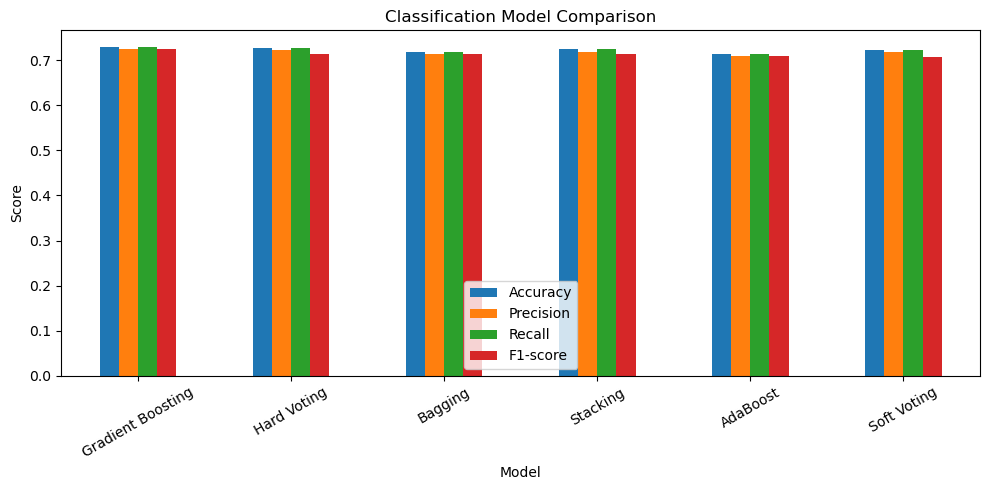

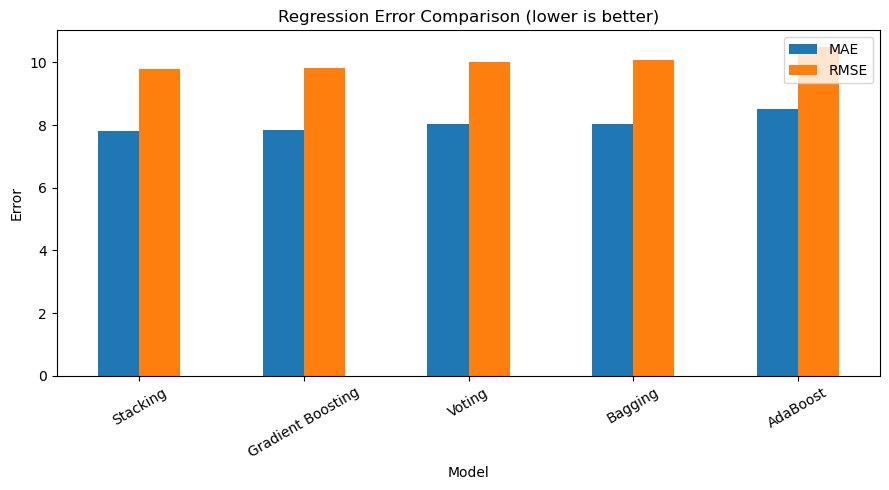

In [15]:

import matplotlib.pyplot as plt

classification_results.plot(
    x="Model", y=["Accuracy", "Precision", "Recall", "F1-score"],
    kind="bar", figsize=(10, 5)
)
plt.title("Classification Model Comparison")
plt.ylabel("Score")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

regression_results.plot(x="Model", y=["MAE", "RMSE"], kind="bar", figsize=(9, 5))
plt.title("Regression Error Comparison (lower is better)")
plt.ylabel("Error")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


## Part G: Final Analysis and Reporting

In [16]:
best_classification = classification_results.iloc[0]
best_regression = regression_results.iloc[0]

print("Best classification model based on F1-score:", best_classification["Model"])
print("F1-score:", round(best_classification["F1-score"], 4))

print("\\nBest regression model based on RMSE:", best_regression["Model"])
print("RMSE:", round(best_regression["RMSE"], 4))
print("MAE:", round(best_regression["MAE"], 4))
print("R2 Score:", round(best_regression["R2 Score"], 4))


Best classification model based on F1-score: Gradient Boosting
F1-score: 0.724
\nBest regression model based on RMSE: Stacking
RMSE: 9.7964
MAE: 7.8221
R2 Score: 0.4864
